# **Operational Fulfillment Analysis**

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [65]:
ecommerce_df = pd.read_csv(
    'dataset/processed/ecommerce_processed.csv',
    parse_dates=['order_date']
)

## 1. Load Only Relevant Columns

In [66]:
OPERATIONAL_COLUMNS = [
    # ORDER STATUS
    'order_status',

    # LOCATION
    'country',
    'shipping_country',

    # SHIPPING
    'shipping_method',
    'shipping_cost_usd',
    'shipping_cost_percent',
    'delivery_days',
    'delivery_speed',
    'shipment_type',

    # CUSTOMER EXPERIENCE
    'rating',

    # FINANCIAL IMPACT
    'net_revenue_usd',
    'profit_usd',
]

In [67]:
operational_df = ecommerce_df[OPERATIONAL_COLUMNS].copy()

In [68]:
operational_df.sample(10)

,order_status,country,shipping_country,shipping_method,shipping_cost_usd,shipping_cost_percent,delivery_days,delivery_speed,shipment_type,rating,net_revenue_usd,profit_usd
244101,Completed,United States,United States,Next Day,15.14,18.36,4,Standard,Domestic,2,82.47,43.62
105180,Completed,Australia,Australia,Standard,19.07,4.05,2,Fast,Domestic,4,470.38,215.82
528626,Completed,Germany,Germany,Standard,22.25,6.59,13,Slow,Domestic,3,337.80,122.28
665075,Completed,Netherlands,Netherlands,Express,24.37,2.93,5,Standard,Domestic,3,832.40,353.96
883158,Completed,France,France,Express,0.44,1.13,10,Slow,Domestic,2,38.98,15.64
966195,Completed,United States,United States,Next Day,8.66,7.40,14,Slow,Domestic,2,116.95,51.97
421949,Completed,Belgium,Belgium,Standard,14.97,4.23,13,Slow,Domestic,1,353.66,171.50
43559,Returned,Netherlands,Netherlands,Express,7.92,0.55,3,Fast,Domestic,4,"1,430.91",697.47
600145,Completed,Spain,Spain,Next Day,5.45,1.05,14,Slow,Domestic,4,516.90,289.40
465108,Completed,Spain,Spain,Economy,7.82,0.67,6,Standard,Domestic,3,"1,162.71",434.49


## 2. Operational Overview (KPIs)

In [69]:
total_orders = operational_df.shape[0]

completed_orders = (
    operational_df['order_status'].eq('Completed').sum()
)

returned_orders = (
    operational_df['order_status'].eq('Returned').sum()
)

cancelled_orders = (
    operational_df['order_status'].eq('Cancelled').sum()
)

processing_orders = (
    operational_df['order_status'].eq('Processing').sum()
)

pending_orders = (
    operational_df['order_status'].eq('Pending').sum()
)

completion_rate = completed_orders / total_orders * 100
return_rate = returned_orders / total_orders * 100
cancellation_rate = cancelled_orders / total_orders * 100

avg_delivery_days = operational_df['delivery_days'].mean()
avg_shipping_cost = operational_df['shipping_cost_usd'].mean()
avg_rating = operational_df['rating'].mean()

In [70]:
print(f"Total Orders          : {total_orders:,}")
print(f"Completion Rate       : {completion_rate:.2f}%")
print(f"Return Rate           : {return_rate:.2f}%")
print(f"Cancellation Rate     : {cancellation_rate:.2f}%")
print(f"Average Delivery Days : {avg_delivery_days:.2f}")
print(f"Average Shipping Cost : ${avg_shipping_cost:,.2f}")
print(f"Average Rating        : {avg_rating:.2f}")

Total Orders          : 1,000,123
Completion Rate       : 70.01%
Return Rate           : 9.99%
Cancellation Rate     : 5.02%
Average Delivery Days : 7.51
Average Shipping Cost : $12.50
Average Rating        : 3.00


## 3. Order Fulfillment Performance

### 3.1 Order Status Distribution

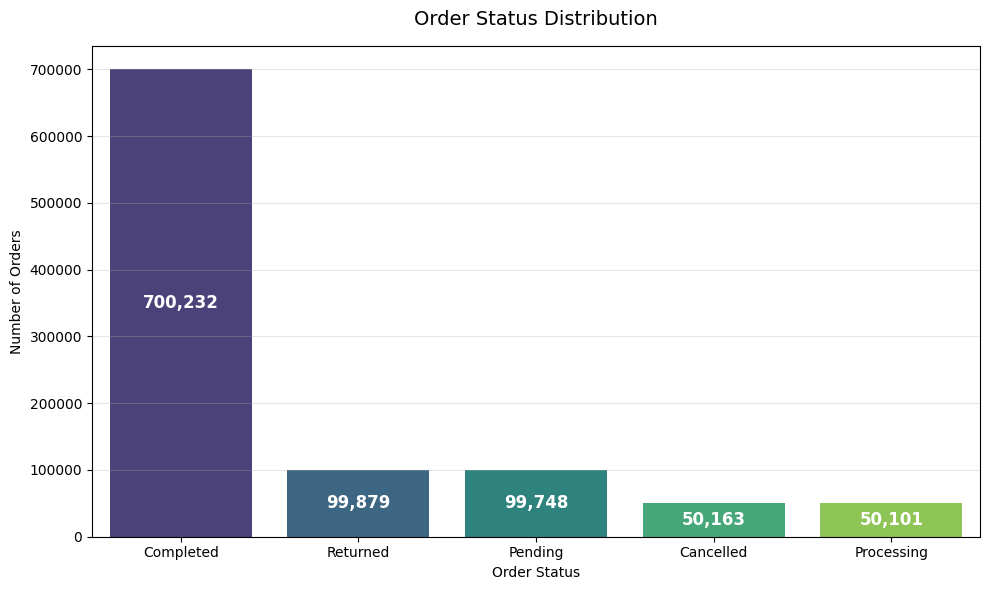

In [71]:
plt.figure(figsize=(10, 6))

status_counts = (
    operational_df['order_status']
    .value_counts()
    .sort_values(ascending=False)
)

ax = sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    palette='viridis',
    hue=status_counts.index,
    legend=False
)

# Add value labels on each marker
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Order Status Distribution', fontsize=14, pad=15)
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**3.1 Order Status Distribution**  
Completed orders are the clear majority at 700,232, representing about 70% of all orders. Returns and pending orders follow at roughly 10% each, while cancellations and processing orders are smaller at about 5% each. This indicates generally strong fulfillment performance, but returns and pending orders remain the two largest operational risks to address.

## 4. Delivery Performance

### 4.1 Distribution of Delivery Days

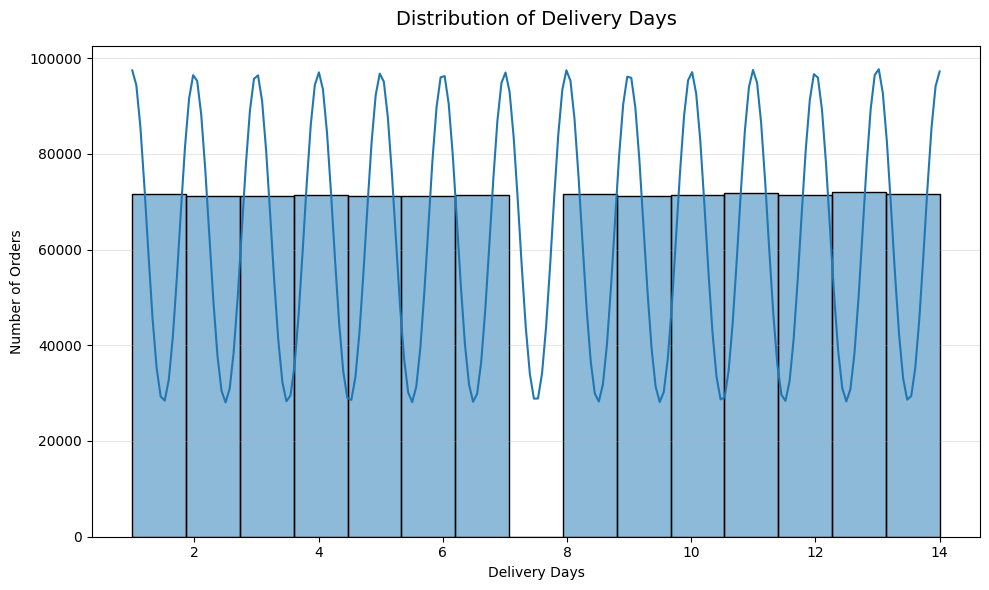

In [72]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=operational_df,
    x='delivery_days',
    bins=15,
    kde=True
)

plt.title('Distribution of Delivery Days', fontsize=14, pad=15)
plt.xlabel('Delivery Days')
plt.ylabel('Number of Orders')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2 Delivery Speed Distribution

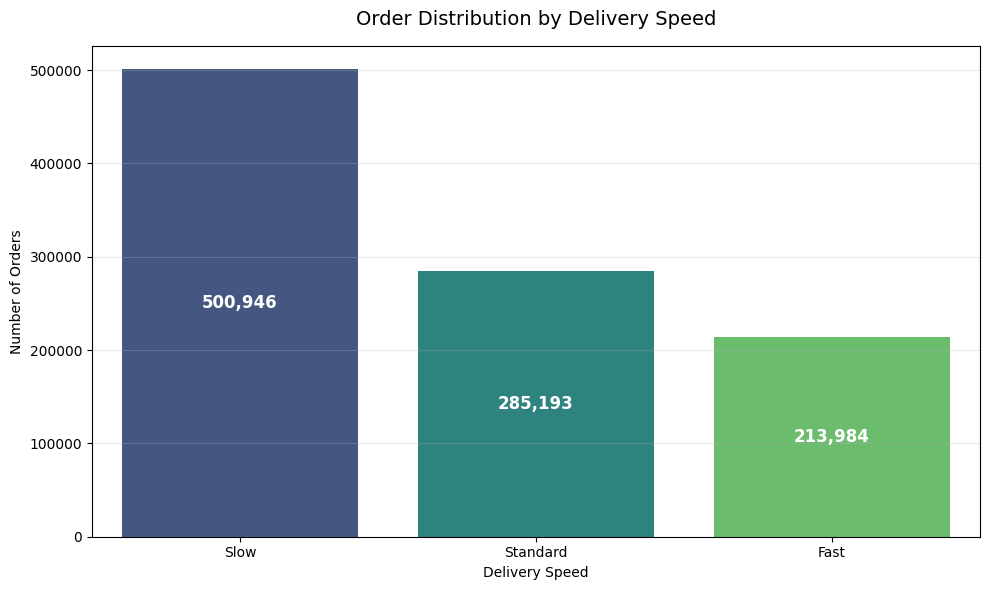

In [73]:
speed_counts = operational_df['delivery_speed'].value_counts()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=speed_counts.index,
    y=speed_counts.values,
    palette='viridis',
    hue=speed_counts.index,
    legend=False
)

# Add value labels on each marker
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Order Distribution by Delivery Speed', fontsize=14, pad=15)
plt.xlabel('Delivery Speed')
plt.ylabel('Number of Orders')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Delivery Days by Shipping Method

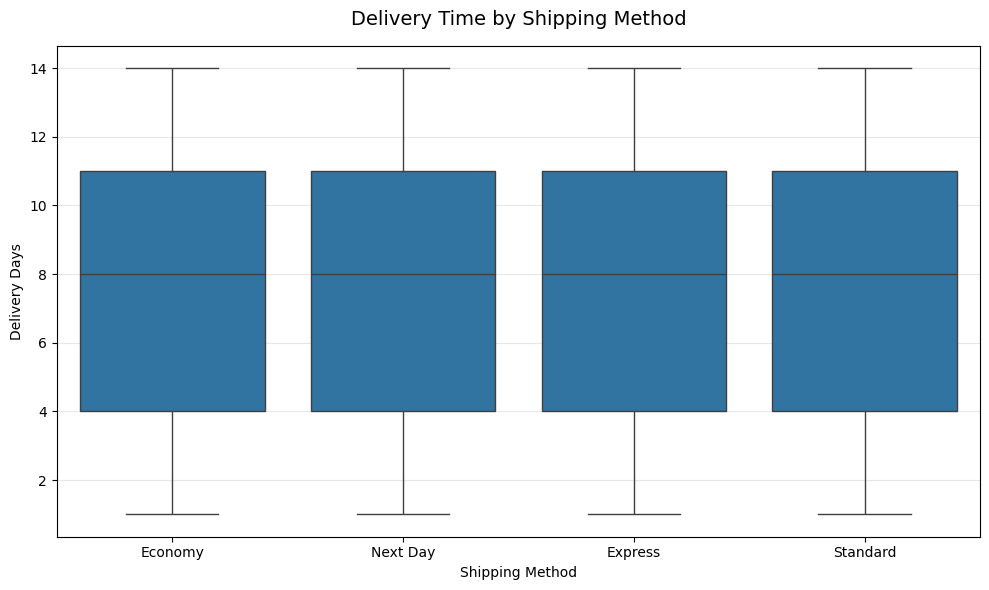

In [74]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=operational_df,
    x='shipping_method',
    y='delivery_days'
)

plt.title('Delivery Time by Shipping Method', fontsize=14, pad=15)
plt.xlabel('Shipping Method')
plt.ylabel('Delivery Days')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**4.1 Distribution of Delivery Days**  
Delivery time ranges from 1 to 14 days, with an average of 7.51 days and a median of 8 days. The distribution is relatively broad and spread across the full delivery range rather than concentrated at one specific duration. This suggests that customers receive inconsistent delivery experiences, making longer-delivery orders an area worth monitoring.

**4.2 Delivery Speed Distribution**  
Slow delivery is the most common category, covering about 50% of orders, or 500,946 orders. Standard delivery represents approximately 29%, while fast delivery is used in about 21% of orders. The high share of slow orders indicates an opportunity to improve service-level consistency and move more orders into faster delivery categories.

**4.3 Delivery Days by Shipping Method**  
The boxplots show almost no practical difference in delivery time among Economy, Standard, Express, and Next Day methods. All four methods have a median of 8 days and averages close to 7.50 days. This means the current shipping methods do not clearly distinguish delivery speed and should be reassessed against service promises and customer expectations.

## 5. Shipping Cost Analysis

### 5.1 Shipping Cost Distribution

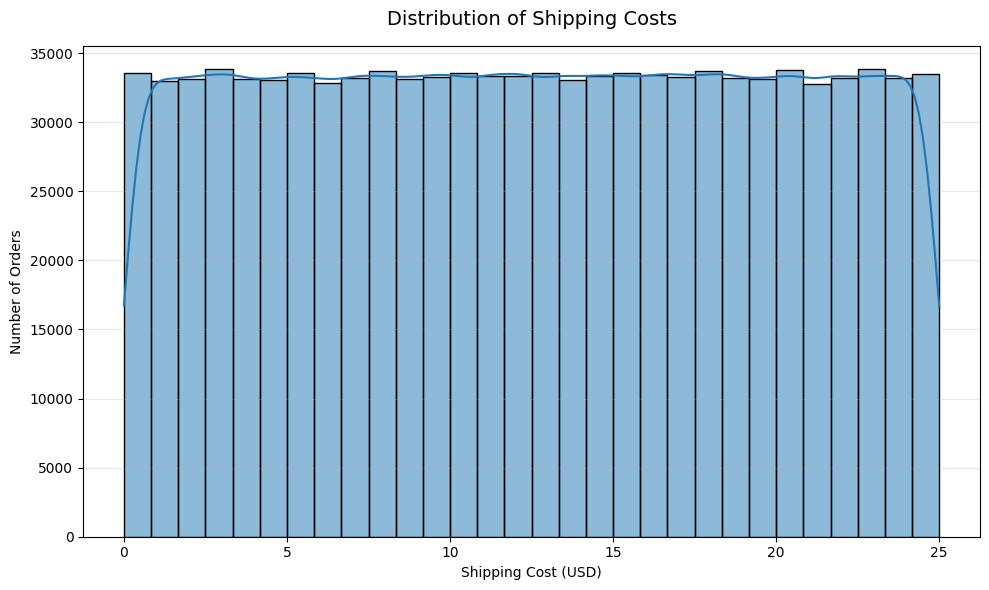

In [75]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=operational_df,
    x='shipping_cost_usd',
    bins=30,
    kde=True
)

plt.title('Distribution of Shipping Costs', fontsize=14, pad=15)
plt.xlabel('Shipping Cost (USD)')
plt.ylabel('Number of Orders')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2 Shipping Cost by Shipping Method

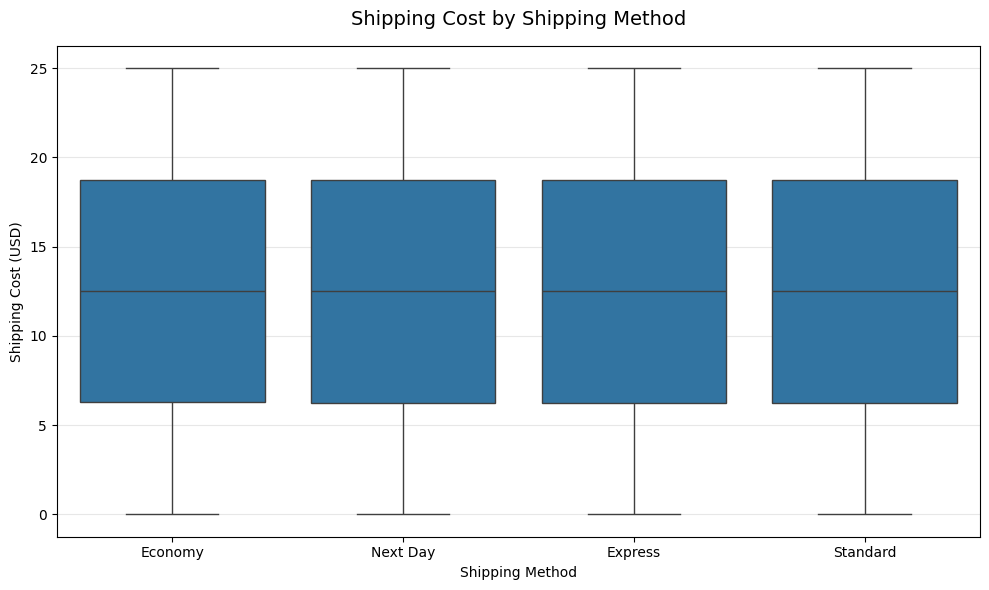

In [76]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=operational_df,
    x='shipping_method',
    y='shipping_cost_usd'
)

plt.title('Shipping Cost by Shipping Method', fontsize=14, pad=15)
plt.xlabel('Shipping Method')
plt.ylabel('Shipping Cost (USD)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**5.1 Shipping Cost Distribution**  
Shipping costs range from $0 to $25, with an average and median of approximately $12.50. The distribution is spread fairly evenly across this range, with no single cost level appearing to dominate strongly. This creates substantial cost variability and indicates that pricing rules should be reviewed for consistency and cost control.

**5.2 Shipping Cost by Shipping Method**  
Economy, Standard, Express, and Next Day shipments have nearly identical average and median shipping costs, all around $12.50. The overlap between the boxplots shows that customers are not being charged clearly different amounts based on the selected service level. This weak cost differentiation may reduce pricing transparency and limit the effectiveness of premium shipping options.

## 6. Delivery Performance vs Customer Experience

### 6.1 Delivery Days vs Rating

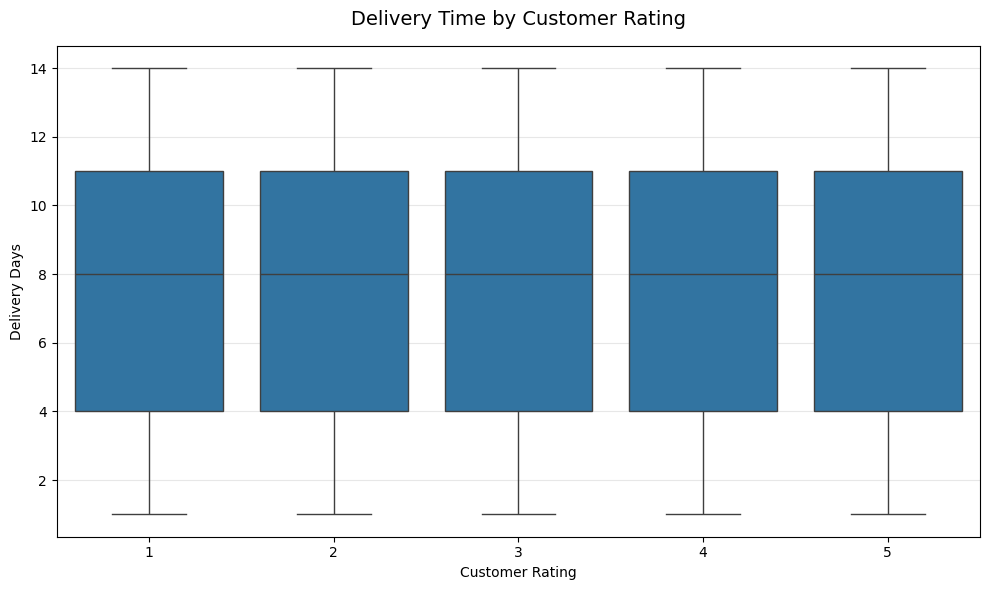

In [77]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=operational_df,
    x='rating',
    y='delivery_days'
)

plt.title('Delivery Time by Customer Rating', fontsize=14, pad=15)
plt.xlabel('Customer Rating')
plt.ylabel('Delivery Days')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**6.1 Delivery Days vs Rating**  
Average delivery time is almost identical for every customer rating, remaining close to 7.50–7.52 days. Median delivery is also 8 days across ratings of 1 through 5, indicating that delivery duration does not materially explain differences in customer ratings in this dataset. The relationship appears weak, so service quality drivers such as damaged items, communication, and order accuracy should be examined alongside delivery speed.

## 7. Operational Performance by Country

### 7.1 Average Delivery Days by Country

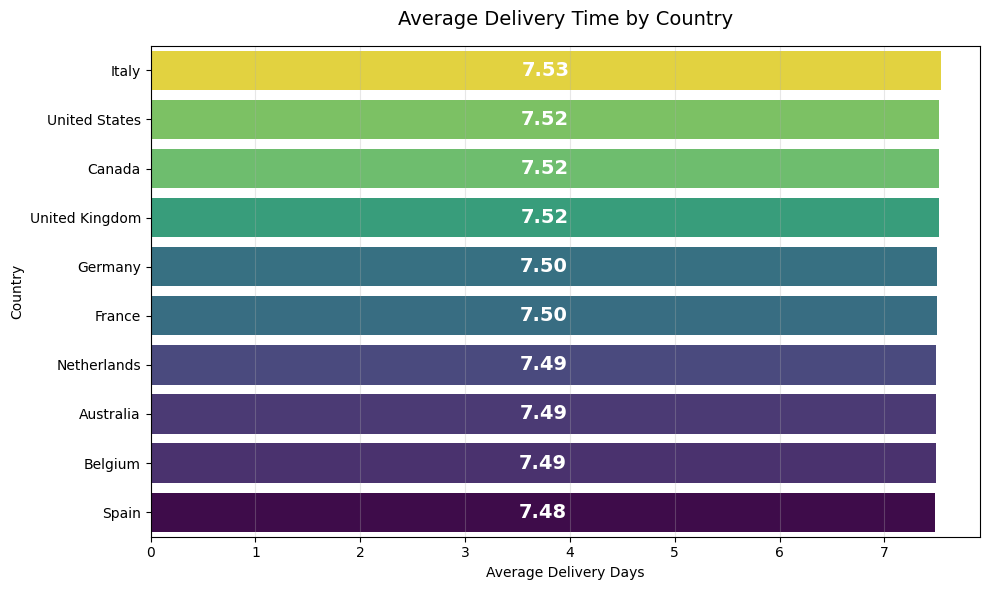

In [78]:
plt.figure(figsize=(10, 6))

country_delivery = (
    operational_df
    .groupby('country')['delivery_days']
    .mean()
    .sort_values(ascending=False)
)

ax = sns.barplot(
    x=country_delivery.values,
    y=country_delivery.index,
    hue=country_delivery.values,
    palette='viridis',
    legend=False
)

# Add value labels on each marker
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{h:,.2f}' for h in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=14,
        fontweight='bold'
    )
    
plt.title('Average Delivery Time by Country', fontsize=14, pad=15)
plt.xlabel('Average Delivery Days')
plt.ylabel('Country')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**7.1 Average Delivery Days by Country**  
Average delivery time is highly consistent across countries, ranging only from approximately 7.48 days in Spain to 7.53 days in Italy. The small country-level differences indicate that delivery performance is well balanced and no market is facing a major operational disadvantage. This also means process standardization appears effective globally, although the slightly slower markets could benefit from targeted carrier and route checks.

## 8. Operational Profitability

### 8.1 Delivery Speed vs Profit Margin

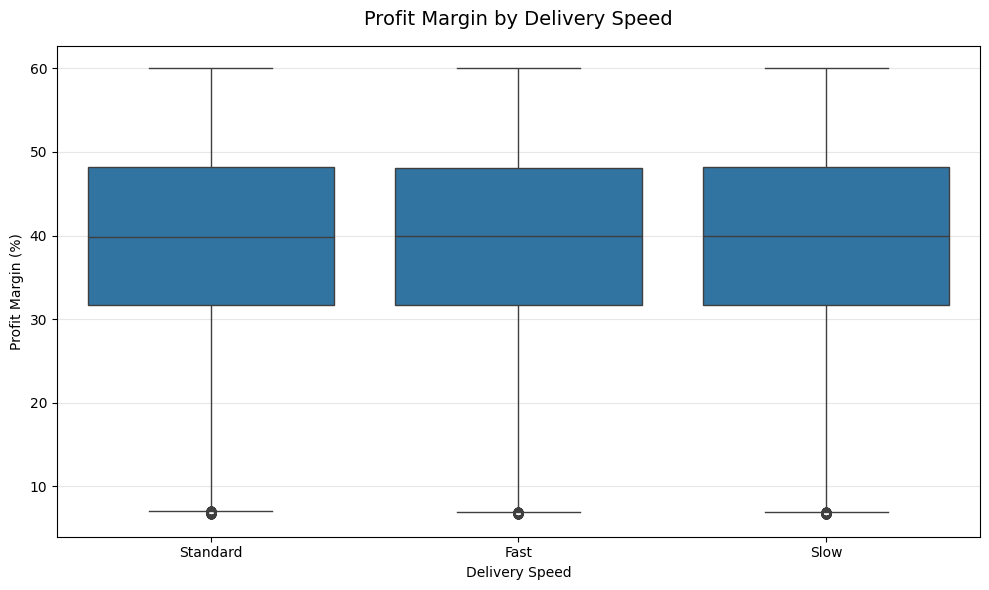

In [79]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=ecommerce_df[
        ['delivery_speed', 'profit_margin_percent']
    ],
    x='delivery_speed',
    y='profit_margin_percent'
)

plt.title('Profit Margin by Delivery Speed', fontsize=14, pad=15)
plt.xlabel('Delivery Speed')
plt.ylabel('Profit Margin (%)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### **Business Insight and Observation**

**8.1 Delivery Speed vs Profit Margin**  
Profit margins are nearly identical across Fast, Standard, and Slow delivery categories, with average margins of approximately 39.45% to 39.47%. The median margins are also closely grouped around 39.9%, showing no clear profitability advantage for any delivery speed. Faster delivery does not appear to reduce profit margins at the aggregate level, so the business can strengthen fast-service availability without evidence of a major margin penalty.

>#### **Summary**
> Order fulfillment is generally stable, as 70% of orders are completed successfully; however, the 10% return rate and 10% pending rate show that operational follow-through still carries meaningful risk. Delivery performance is relatively consistent across countries, but delivery times vary widely across individual orders, with half of shipments classified as slow and little practical difference between shipping methods. Shipping prices are also nearly identical across service levels, suggesting that premium options do not currently provide clear operational or pricing differentiation. Delivery duration has little visible relationship with customer ratings, so improvements should also address broader experience factors such as order accuracy, communication, and damage handling. Finally, delivery speed does not materially affect profit margins, giving the company room to improve faster fulfillment services without an immediate expectation of lower profitability.